# 02 — Experiments: baseline → forest → boosting, and the `duration` leak

**CallWise · EC-417 P05 · Roll Nos. 623169 & 623195**

This notebook walks through the experiments behind the results table and **runs top to bottom in about a minute**.

* The full hyperparameter search (about 17 minutes) lives in `python -m src.train`. Here we **re-fit only the
  configuration it chose** for each model (seed 42) and check that the validation scores match
  `results/val_metrics.csv` exactly. This shows the saved results are reproducible.
* **The test set is not scored here.** It was scored once, by `python -m src.train --final`; section 6 only
  reads `results/metrics.csv`.

Needs: `pip install -r requirements.txt`. The dataset is downloaded automatically if `data/raw/` is empty.

In [1]:
import subprocess, sys, pathlib, time
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import data, models, evaluate
from src import plotstyle as ps
from src.metrics import best_f1_threshold, score

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.calibration import calibration_curve

ps.apply()
pd.set_option("display.width", 160)
RESULTS = ROOT / "results"
SEED = 42

if not data.DATA_PATH.exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "get_data.py")], check=True, cwd=ROOT)
X, y = data.load()
print(X.shape, f"positive rate = {y.mean():.3f}")

(45211, 17) positive rate = 0.117


## 1. The leak-free split

Split first, fit later. The test set (15%) is drawn once with seed 42 and is **the same for every seed and every
model**; the seed only changes how the remaining 85% is divided into train (70%) and validation (15%).
Stratifying keeps the 11.7% positive rate in every part.

In [2]:
X_tr, X_val, X_test, y_tr, y_val, y_test = data.split(X, y, SEED)
pd.DataFrame({"rows": [len(y_tr), len(y_val), len(y_test)],
              "share": [len(y_tr) / len(y), len(y_val) / len(y), len(y_test) / len(y)],
              "subscribers": [y_tr.sum(), y_val.sum(), y_test.sum()],
              "positive_rate": [y_tr.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).round(3)

,rows,share,subscribers,positive_rate
train,31647,0.70,3703,0.117
validation,6782,0.15,793,0.117
test,6782,0.15,793,0.117


In [3]:
# The test rows are identical for seeds 42, 43, 44; train/validation differ.
splits = {s: data.split(X, y, s) for s in data.SEEDS}
same_test = all(splits[s][2].index.equals(splits[SEED][2].index) for s in data.SEEDS)
same_train = all(splits[s][0].index.equals(splits[SEED][0].index) for s in data.SEEDS)
print("test set identical across seeds:", same_test)
print("train set identical across seeds:", same_train)
assert same_test and not same_train

test set identical across seeds: True
train set identical across seeds: False


## 2. Re-fit the chosen configurations (seed 42, both feature sets)

`src.train` searched the hyperparameters on the **training and validation parts only**:

| Model | How its configuration was chosen |
|---|---|
| Decision tree (baseline) | `max_depth` × `min_samples_leaf` by 5-fold stratified CV on the training part |
| Random forest (main model) | 18 configurations compared on validation PR-AUC |
| HGB, `class_weight="balanced"` (improvement) | 24 configurations on validation PR-AUC; early stopping picks the number of trees |
| HGB, unweighted (ablation) | the weighted model's configuration with `class_weight=None`, so only the weighting changes |

Below, each chosen configuration is read back from the CSVs and fitted once. Encoders sit inside the `Pipeline`,
so they only ever see training rows. The F1 threshold is picked on validation, as in `src.train`.

In [4]:
val = pd.read_csv(RESULTS / "val_metrics.csv")
forest_search = pd.read_csv(RESULTS / "forest_val_search.csv")
hgb_search = pd.read_csv(RESULTS / "hgb_val_search.csv")

def stored(model, fs, metric, seed=SEED):
    r = val[(val.model == model) & (val.feature_set == fs) & (val.seed == seed) & (val.metric == metric)]
    return float(r["value"].iloc[0])

def chosen(search, fs, seed=SEED):
    return search[(search.feature_set == fs) & (search.seed == seed) & search.chosen].iloc[0]

def as_number(v):
    # max_features is stored as "sqrt" or "0.5"
    try:
        return float(v)
    except ValueError:
        return v

def build(name, fs):
    if name == "dummy":
        return models.dummy()
    if name == "tree":
        depth = int(stored("tree", fs, "best_max_depth"))
        return models.tree(SEED).set_params(
            clf__max_depth=None if depth == -1 else depth,
            clf__min_samples_leaf=int(stored("tree", fs, "best_min_samples_leaf")))
    if name == "forest":
        r = chosen(forest_search, fs)
        return models.forest(SEED, max_depth=None if pd.isna(r.max_depth) else int(r.max_depth),
                             min_samples_leaf=int(r.min_samples_leaf),
                             max_features=as_number(r.max_features))
    r = chosen(hgb_search, fs)
    p = dict(learning_rate=float(r.learning_rate), max_leaf_nodes=int(r.max_leaf_nodes),
             min_samples_leaf=int(r.min_samples_leaf), l2_regularization=float(r.l2_regularization))
    return models.hgb(SEED, weighted=(name == "hgb"), **p)

NAMES = ["dummy", "tree", "forest", "hgb", "hgb_unweighted"]
rows, fitted = [], {}
for fs in data.FEATURE_SETS:
    Xf = data.feature_set(X, fs)
    X_tr, X_val, _, y_tr, y_val, _ = data.split(Xf, y, SEED)   # the test part is not used here
    for name in NAMES:
        m = build(name, fs)
        t = time.perf_counter()
        m.fit(X_tr, y_tr)
        fit_s = time.perf_counter() - t
        p_val = m.predict_proba(X_val)[:, 1]
        s = score(y_val, p_val, best_f1_threshold(y_val, p_val))
        fitted[(name, fs)] = (m, p_val, y_val)
        rows.append({"model": name, "feature_set": fs, "val_pr_auc": s["pr_auc"],
                     "stored_pr_auc": stored(name, fs, "pr_auc"), "val_roc_auc": s["roc_auc"],
                     "brier": s["brier"], "fit_s": fit_s})

refit = pd.DataFrame(rows)
refit["matches_stored"] = (refit.val_pr_auc - refit.stored_pr_auc).abs() < 1e-9
refit.round(4)

,model,feature_set,val_pr_auc,stored_pr_auc,val_roc_auc,brier,fit_s,matches_stored
0,dummy,DEPLOYABLE,0.1169,0.1169,0.5000,0.1033,0.0014,True
1,tree,DEPLOYABLE,0.3823,0.3823,0.7526,0.0883,0.2188,True
2,forest,DEPLOYABLE,0.4474,0.4474,0.8005,0.0822,0.8461,True
3,hgb,DEPLOYABLE,0.4564,0.4564,0.7982,0.1474,2.9922,True
4,hgb_unweighted,DEPLOYABLE,0.4398,0.4398,0.8023,0.0821,2.1125,True
5,dummy,FULL,0.1169,0.1169,0.5000,0.1033,0.0016,True
6,tree,FULL,0.5431,0.5431,0.8976,0.0702,0.2347,True
7,forest,FULL,0.6079,0.6079,0.9258,0.0649,0.9456,True
8,hgb,FULL,0.6195,0.6195,0.9300,0.0970,1.8246,True
9,hgb_unweighted,FULL,0.6171,0.6171,0.9321,0.0632,1.4791,True


In [5]:
assert refit.matches_stored.all(), "re-fitted scores differ from results/val_metrics.csv"
print("All", len(refit), "re-fitted models reproduce the stored validation PR-AUC exactly.")

All 10 re-fitted models reproduce the stored validation PR-AUC exactly.


## 3. The `duration` leak

`duration` is the length of the call, so it is only known **after** the call has ended. A model that uses it
cannot be used to decide whom to call. Every model was therefore trained twice: on **FULL** (with `duration`,
reference only) and on **DEPLOYABLE** (without it). All headline numbers use DEPLOYABLE.

In [6]:
leak = refit.pivot(index="model", columns="feature_set", values="val_pr_auc").loc[NAMES]
leak["gap"] = leak.FULL - leak.DEPLOYABLE
leak["share_of_full_score"] = leak.gap / leak.FULL
leak.round(3)

feature_set,DEPLOYABLE,FULL,gap,share_of_full_score
model,,,,
dummy,0.117,0.117,0.000,0.000
tree,0.382,0.543,0.161,0.296
forest,0.447,0.608,0.161,0.264
hgb,0.456,0.620,0.163,0.263
hgb_unweighted,0.440,0.617,0.177,0.287


Adding `duration` raises validation PR-AUC by 0.16–0.18 for every real model (seed 42), about 26–30% of the leaky score. The ranking of the
models does not change, but every score is inflated. The decision tree gains the most in relative terms, because
a single split on call length already separates many subscribers.

## 4. The improvement and its ablation: does class weighting help?

`class_weight="balanced"` gives each "yes" about 7.5× the weight of a "no". The ablation keeps the weighted
model's exact configuration and switches the weighting off.

In [7]:
abl = refit[(refit.feature_set == "DEPLOYABLE") & refit.model.isin(["forest", "hgb", "hgb_unweighted"])]
abl = abl.set_index("model")[["val_pr_auc", "val_roc_auc", "brier"]]
abl["mean_predicted"] = [fitted[(m, "DEPLOYABLE")][1].mean() for m in abl.index]
abl["actual_rate"] = y_val.mean()
abl.round(3)

,val_pr_auc,val_roc_auc,brier,mean_predicted,actual_rate
model,,,,,
forest,0.447,0.800,0.082,0.117,0.117
hgb,0.456,0.798,0.147,0.352,0.117
hgb_unweighted,0.440,0.802,0.082,0.115,0.117


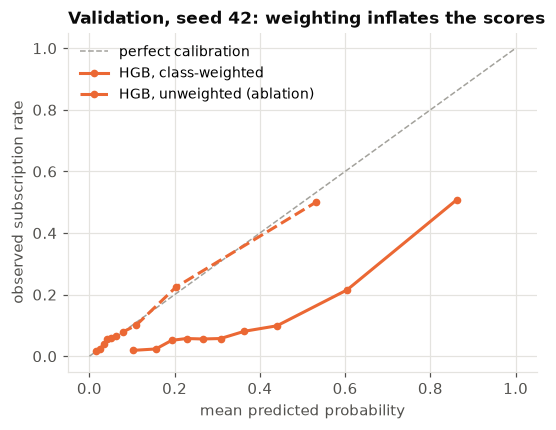

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot([0, 1], [0, 1], color=ps.NO_COLOR, linestyle="--", linewidth=1, label="perfect calibration")
for name, style in [("hgb", "-"), ("hgb_unweighted", "--")]:
    _, p_val, yv = fitted[(name, "DEPLOYABLE")]
    frac, mean_p = calibration_curve(yv, p_val, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", markersize=4, color=ps.SERIES[1], linestyle=style,
            label=evaluate.LABELS[name])
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed subscription rate")
ax.set_title("Validation, seed 42: weighting inflates the scores", fontsize=11)
ax.legend(loc="upper left", fontsize=9)
plt.show()

For seed 42 the weighted model has the best validation PR-AUC, but that is not stable across seeds (section 5):
over three seeds the ranking difference is within noise. The **Brier score** shows a clear cost: the weighted
model's average prediction is about three times the true 11.7% rate (0.35 vs 0.117), so its scores can be used for **ranking** but not
read as probabilities. Re-weighting shifts the scores up without changing their order much.

## 5. Three seeds: is the difference larger than the noise?

Mean ± std of the validation scores over seeds 42, 43, 44, from the full `src.train` run.

In [9]:
evaluate.summary(RESULTS / "val_metrics.csv", metrics=("pr_auc", "roc_auc", "brier", "train_time_s"))

metric                             pr_auc        roc_auc          brier   train_time_s
feature_set model                                                                     
DEPLOYABLE  dummy           0.117 ± 0.000  0.500 ± 0.000  0.103 ± 0.000  0.001 ± 0.000
            tree            0.405 ± 0.021  0.760 ± 0.006  0.086 ± 0.002  0.306 ± 0.086
            forest          0.458 ± 0.013  0.796 ± 0.006  0.081 ± 0.001  3.845 ± 1.634
            hgb             0.460 ± 0.008  0.798 ± 0.003  0.150 ± 0.008  1.691 ± 0.148
            hgb_unweighted  0.454 ± 0.013  0.798 ± 0.007  0.081 ± 0.001  1.235 ± 0.961
FULL        dummy           0.117 ± 0.000  0.500 ± 0.000  0.103 ± 0.000  0.001 ± 0.000
            tree            0.551 ± 0.010  0.903 ± 0.011  0.069 ± 0.002  0.353 ± 0.034
            forest          0.627 ± 0.017  0.930 ± 0.006  0.063 ± 0.002  1.779 ± 0.132
            hgb             0.638 ± 0.016  0.936 ± 0.005  0.095 ± 0.007  1.906 ± 1.831
            hgb_unweighted  0.628 ± 0.010  0.936 ± 0.004  0.062 ± 0.001  1.129 ± 0.415

The ensembles beat the single tree by more than twice its seed-to-seed spread. Forest, weighted HGB and
unweighted HGB are within about one standard deviation of each other on validation.

## 6. Final test results (scored once, read from `results/metrics.csv`)

The test set was scored a single time by `python -m src.train --final`, with every hyperparameter and threshold
already frozen on validation. Nothing in this notebook re-scores it.

In [10]:
evaluate.summary(RESULTS / "metrics.csv",
                 metrics=("pr_auc", "roc_auc", "brier", "precision", "recall", "train_time_s"))

metric                             pr_auc        roc_auc          brier      precision         recall   train_time_s
feature_set model                                                                                                   
DEPLOYABLE  dummy           0.117 ± 0.000  0.500 ± 0.000  0.103 ± 0.000  0.117 ± 0.000  1.000 ± 0.000  0.001 ± 0.000
            tree            0.399 ± 0.003  0.755 ± 0.001  0.087 ± 0.001  0.435 ± 0.004  0.475 ± 0.012  0.306 ± 0.086
            forest          0.438 ± 0.005  0.796 ± 0.002  0.083 ± 0.000  0.443 ± 0.002  0.521 ± 0.011  3.845 ± 1.634
            hgb             0.441 ± 0.007  0.797 ± 0.001  0.149 ± 0.008  0.449 ± 0.015  0.520 ± 0.013  1.691 ± 0.148
            hgb_unweighted  0.446 ± 0.003  0.801 ± 0.002  0.082 ± 0.001  0.457 ± 0.019  0.497 ± 0.020  1.235 ± 0.961
FULL        dummy           0.117 ± 0.000  0.500 ± 0.000  0.103 ± 0.000  0.117 ± 0.000  1.000 ± 0.000  0.001 ± 0.000
            tree            0.551 ± 0.007  0.901 ± 0.005  0.069 ± 0.001  0.510 ± 0.034  0.683 ± 0.054  0.353 ± 0.034
            forest          0.609 ± 0.006  0.927 ± 0.000  0.064 ± 0.000  0.534 ± 0.019  0.715 ± 0.036  1.779 ± 0.132
            hgb             0.625 ± 0.004  0.931 ± 0.001  0.095 ± 0.004  0.567 ± 0.010  0.683 ± 0.024  1.906 ± 1.831
            hgb_unweighted  0.626 ± 0.004  0.931 ± 0.001  0.063 ± 0.001  0.545 ± 0.028  0.733 ± 0.047  1.129 ± 0.415

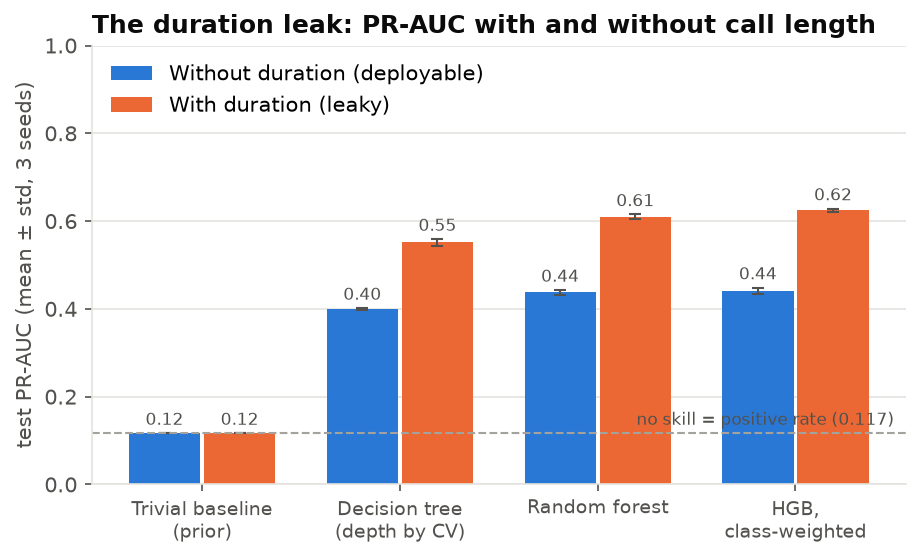

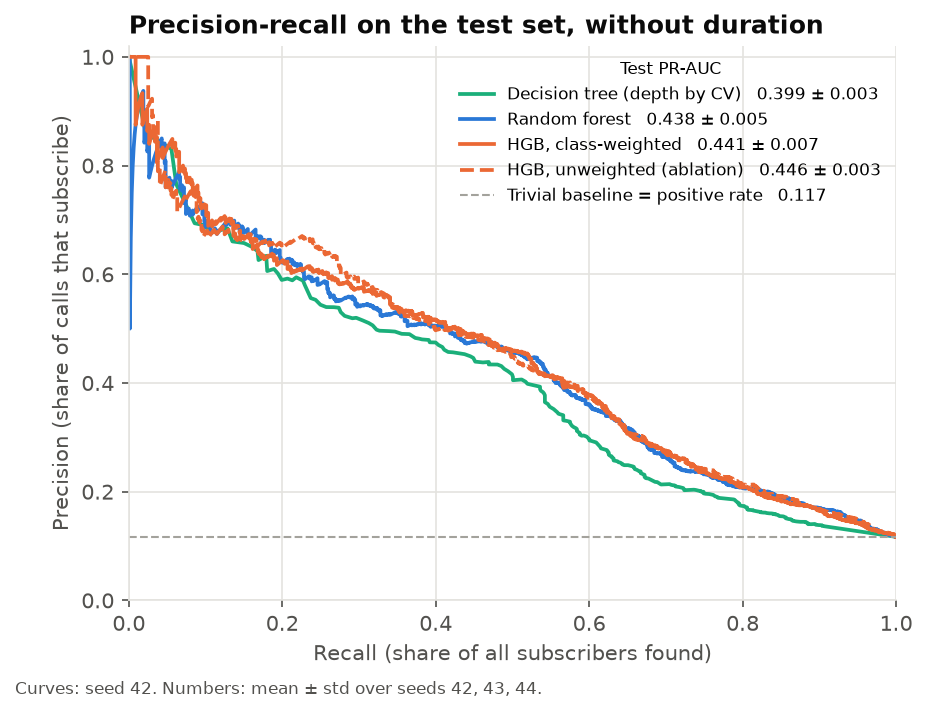

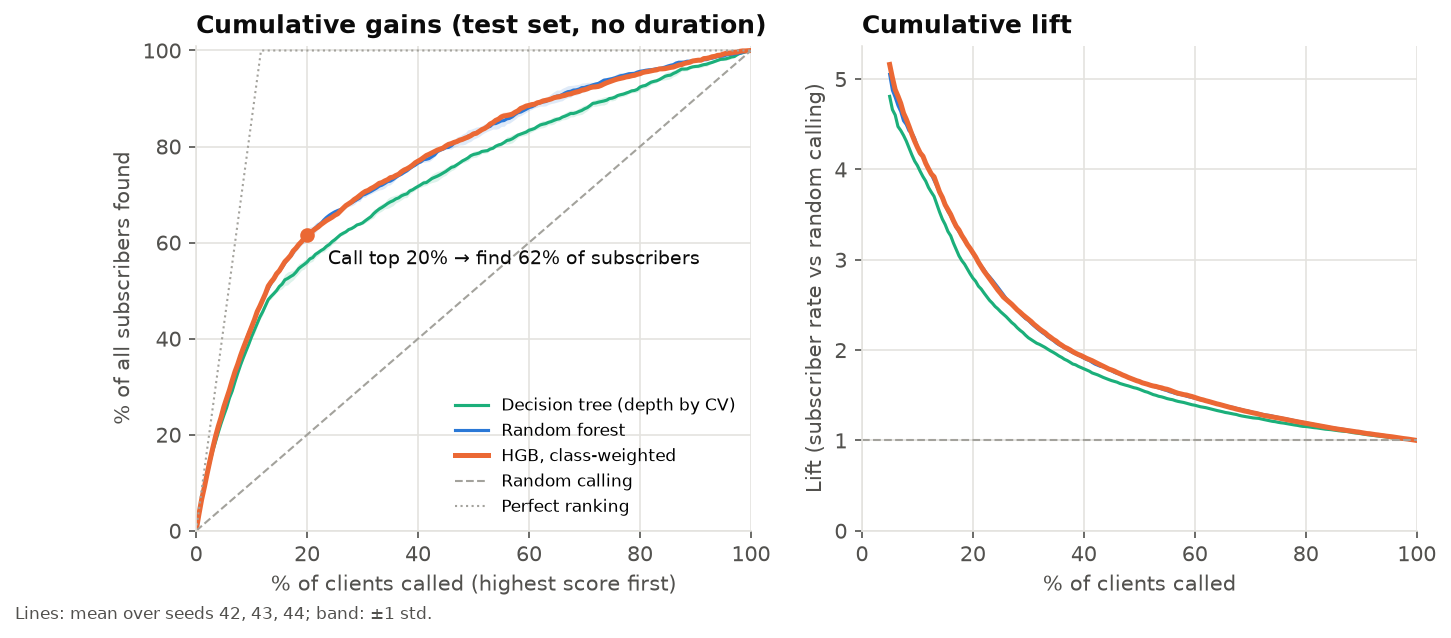

In [11]:
for f in ["F2b_duration_gap_test.png", "F3_pr_curves.png", "F5_gains_lift.png"]:
    display(Image(filename=str(RESULTS / "figures" / f), width=720))

## 7. Takeaways

1. **Every model beats the trivial baseline** (PR-AUC 0.117), and the ensembles beat the decision tree
   (test PR-AUC about 0.44 vs 0.40).
2. **Boosting ties the forest** (0.441 ± 0.007 vs 0.438 ± 0.005): the difference is within one standard deviation.
3. **Class weighting does not help ranking and hurts calibration.** The unweighted ablation scores 0.446 ± 0.003
   on test, and its Brier score is about half that of the weighted model.
4. **The leak is large.** `duration` adds 0.15–0.18 test PR-AUC to every model, but it is not available before the
   call, so the DEPLOYABLE numbers are the honest ones.
5. **Validation was slightly optimistic** (about 0.02 above test), as expected after picking the best of many
   configurations on validation. The model ranking did not change.

Figures F3–F9, the error analysis and the business view (lift, profit) are produced by `python -m src.evaluate`;
see the README and `results/ERROR_ANALYSIS.md`.